# First name came out as van: six name splitters against twelve naming conventions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/name-splitter/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/name-splitter/demo.ipynb)

A CRM export writes `van den Broek, Pieter`, the import script splits on the first space, and the welcome email
opens "Dear van". This notebook runs six ways of splitting a full name into given + family over 51 fictional names
in 12 naming conventions, each hand-labelled from the person's own convention.

1. The engine
2. The scoreboard
3. Which conventions each splitter breaks
4. Dear Dr., Dear van: greetings that came out as a title or particle
5. The ceiling: what no splitter can fix
6. The chart
7. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Truth is two fields per row: **given** (the name you
greet them by) and **family** (the surname as filed, particles included; empty for mononyms and Malay bin/binti
patronymics). Nothing is random, so every number below matches `evidence.txt` exactly.

In [1]:
from __future__ import annotations

# !pip install nameparser==2.5.0   # uncomment on Colab / Binder
from collections import Counter
from typing import Callable, Dict, List, Tuple

import matplotlib.pyplot as plt
from nameparser import HumanName


class _E:  # evidence.py refers to the engine as E
    pass

CORPUS: List[Tuple[str, str, str, str]] = [
    # plain given + family
    ("Grace Holloway", "plain", "Grace", "Holloway"),
    ("Daniel Okafor", "plain", "Daniel", "Okafor"),
    ("Priya Raman", "plain", "Priya", "Raman"),
    ("Lucas Moreau", "plain", "Lucas", "Moreau"),
    ("Hannah Becker", "plain", "Hannah", "Becker"),
    ("Samuel Adeyemi", "plain", "Samuel", "Adeyemi"),
    # middle names
    ("Thomas Edward Barlow", "middle name", "Thomas", "Barlow"),
    ("Claire Louise Fenwick", "middle name", "Claire", "Fenwick"),
    ("Michael James Ortega", "middle name", "Michael", "Ortega"),
    ("Aisha Noor Rahman", "middle name", "Aisha", "Rahman"),
    # surname particles (Dutch, German, French, Italian, Arabic)
    ("Pieter van den Broek", "particle", "Pieter", "van den Broek"),
    ("Anna von Halden", "particle", "Anna", "von Halden"),
    ("Luc de la Fontaine", "particle", "Luc", "de la Fontaine"),
    ("Marco di Stefano", "particle", "Marco", "di Stefano"),
    ("Sophie De Smet", "particle", "Sophie", "De Smet"),
    ("Omar al Rashid", "particle", "Omar", "al Rashid"),
    ("Vincent van der Berg", "particle", "Vincent", "van der Berg"),
    # Iberian: two surnames (paternal + maternal), sometimes two given names
    ("Ana María Pérez López", "two surnames", "Ana María", "Pérez López"),
    ("Carlos Ruiz Delgado", "two surnames", "Carlos", "Ruiz Delgado"),
    ("Lucía Fernández Ortiz", "two surnames", "Lucía", "Fernández Ortiz"),
    ("João Silva Santos", "two surnames", "João", "Silva Santos"),
    ("José Luis Navarro Gil", "two surnames", "José Luis", "Navarro Gil"),
    # family name first, as written natively (Chinese, Korean, Japanese, Hungarian, Vietnamese)
    ("Wang Fang", "family first", "Fang", "Wang"),
    ("Kim Min-jun", "family first", "Min-jun", "Kim"),
    ("Tanaka Yuki", "family first", "Yuki", "Tanaka"),
    ("Nagy Eszter", "family first", "Eszter", "Nagy"),
    ("Nguyen Van An", "family first", "An", "Nguyen"),
    ("Chen Lin", "family first", "Lin", "Chen"),
    # East Asian names already turned round into Western order
    ("Lin Chen", "Western-ordered East Asian", "Lin", "Chen"),
    ("Chen Lin", "Western-ordered East Asian", "Chen", "Lin"),
    ("Min-jun Park", "Western-ordered East Asian", "Min-jun", "Park"),
    # titles and suffixes
    ("Dr. Robert Hale Jr.", "title or suffix", "Robert", "Hale"),
    ("Margaret Osei PhD", "title or suffix", "Margaret", "Osei"),
    ("James Whitmore III", "title or suffix", "James", "Whitmore"),
    ("Mrs. Ellen Park", "title or suffix", "Ellen", "Park"),
    ("Prof. Henrik Dahl", "title or suffix", "Henrik", "Dahl"),
    # one name only
    ("Wiratmo", "mononym", "Wiratmo", ""),
    ("Suwarni", "mononym", "Suwarni", ""),
    ("Teodora", "mononym", "Teodora", ""),
    # Malay patronymics: "bin/binti <father>" is not a family name
    ("Abdullah bin Ahmad", "patronymic", "Abdullah", ""),
    ("Siti binti Hassan", "patronymic", "Siti", ""),
    ("Farid bin Yusof", "patronymic", "Farid", ""),
    # hyphenated surnames
    ("Emily Clarke-Hughes", "hyphenated", "Emily", "Clarke-Hughes"),
    ("Hamid Al-Farsi", "hyphenated", "Hamid", "Al-Farsi"),
    ("Jean-Luc Marchand", "hyphenated", "Jean-Luc", "Marchand"),
    # English double-barrelled surnames WITHOUT a hyphen (same shape as a middle name)
    ("Rupert Ashby Lowe", "double-barrelled", "Rupert", "Ashby Lowe"),
    ("Harriet Vane Tempest", "double-barrelled", "Harriet", "Vane Tempest"),
    # exports that write "Family, Given"
    ("van den Broek, Pieter", "comma inverted", "Pieter", "van den Broek"),
    ("Hale, Robert", "comma inverted", "Robert", "Hale"),
    ("Pérez López, Ana María", "comma inverted", "Ana María", "Pérez López"),
    ("Okafor, Daniel", "comma inverted", "Daniel", "Okafor"),
]


SHARE: Dict[str, float] = {
    "plain": 0.51,
    "middle name": 0.12,
    "particle": 0.04,
    "two surnames": 0.06,
    "family first": 0.05,
    "Western-ordered East Asian": 0.06,
    "title or suffix": 0.03,
    "mononym": 0.005,
    "patronymic": 0.01,
    "hyphenated": 0.04,
    "double-barrelled": 0.005,
    "comma inverted": 0.07,
}


PARTICLES = {"van", "von", "de", "der", "den", "la", "le", "du", "di", "da", "del", "al", "el", "ter", "ten"}


TITLES = {"dr.", "dr", "mr.", "mr", "mrs.", "mrs", "ms.", "ms", "prof.", "prof"}


SUFFIXES = {"jr.", "jr", "sr.", "sr", "ii", "iii", "iv", "phd", "md"}


PATRONYM = {"bin", "binti", "ibn"}


CJK_SURNAMES = {"wang", "li", "zhang", "liu", "chen", "yang", "kim", "lee", "park", "nguyen", "tanaka", "lin"}


Split = Tuple[str, str]


def _first_space(s: str) -> Split:
    """given, family = s.split(" ", 1) - the one-liner in most import scripts."""
    p = s.split(" ", 1)
    return p[0], p[1] if len(p) > 1 else ""


def _last_space(s: str) -> Split:
    """given, family = s.rsplit(" ", 1) - 'the surname is the last word'."""
    p = s.rsplit(" ", 1)
    return (p[0], p[1]) if len(p) > 1 else (p[0], "")


def _first_last(s: str) -> Split:
    """Spreadsheet formula: LEFT to the first space, RIGHT from the last space; middle words dropped."""
    t = s.split()
    return t[0], t[-1] if len(t) > 1 else ""


def _strip_affixes(s: str) -> List[str]:
    return [w for w in s.replace(",", " ").split() if w.lower() not in TITLES | SUFFIXES]


def _particle_aware(s: str) -> Split:
    """Comma-aware, strips titles and suffixes, and pulls lowercase particles into the surname."""
    if "," in s:
        fam, giv = (x.strip() for x in s.split(",", 1))
        return giv, fam
    t = _strip_affixes(s)
    if len(t) == 1:
        return t[0], ""
    i = len(t) - 1
    while i > 1 and t[i - 1].lower() in PARTICLES:
        i -= 1
    return " ".join(t[:i]), " ".join(t[i:])


def _cjk_order(s: str) -> Split:
    """Particle-aware, plus: if the first word is a common East Asian surname, treat the name as family-first."""
    t = s.split()
    if "," not in s and len(t) in (2, 3) and t[0].lower() in CJK_SURNAMES:
        return t[-1] if len(t) == 3 else t[1], t[0]
    return _particle_aware(s)


def _nameparser(s: str) -> Split:
    h = HumanName(s)
    return h.first, h.last


SPLITTERS: Dict[str, Callable[[str], Split]] = {
    'split(" ", 1)': _first_space,
    'rsplit(" ", 1)': _last_space,
    "first + last word": _first_last,
    "particle-aware rules": _particle_aware,
    "+ East Asian surname list": _cjk_order,
    "nameparser 2.5": _nameparser,
}


def shape(s: str) -> str:
    """What a rule over word POSITIONS can see: comma, word count, and each word's class (not the word itself)."""
    cls = []
    for w in s.replace(",", " ").split():
        lw = w.lower()
        cls.append(
            "t"
            if lw in TITLES
            else "s"
            if lw in SUFFIXES
            else "p"
            if lw in PARTICLES
            else "b"
            if lw in PATRONYM
            else "W"
        )
    return ("," if "," in s else "") + "".join(cls)


def roles(s: str, given: str, family: str) -> str:
    """Which word of `s` is given (G), family (F) or neither (-): the split expressed as positions."""
    g, f = given.split(), family.split()
    out = []
    for w in s.replace(",", " ").split():
        if w in g:
            out.append("G")
            g.remove(w)
        elif w in f:
            out.append("F")
            f.remove(w)
        else:
            out.append("-")
    return "".join(out)


def ceiling() -> Dict:
    """Two upper bounds on any splitter that sees only the string.

    by string: the same string with two truths ("Chen Lin") - nothing can get both.
    by shape : rows a position rule cannot tell apart ("Thomas Edward Barlow" vs "Rupert Ashby Lowe" vs
               "Carlos Ruiz Delgado" are all W W W) - the best any rule over word classes can do, without a
               dictionary of which words are surnames.
    """
    by_s: Dict[str, Counter] = {}
    by_shape: Dict[str, Counter] = {}
    for s, _, g, f in CORPUS:
        by_s.setdefault(s, Counter())[(g, f)] += 1
        by_shape.setdefault(shape(s), Counter())[roles(s, g, f)] += 1
    return {
        "by_string": sum(c.most_common(1)[0][1] for c in by_s.values()),
        "ambiguous_strings": sorted(s for s, c in by_s.items() if len(c) > 1),
        "by_shape": sum(c.most_common(1)[0][1] for c in by_shape.values()),
        "WWW": dict(by_shape.get("WWW", Counter())),
    }


def score(name: str, share: Dict[str, float] = SHARE) -> Dict:
    """Per splitter: rows with given wrong, family wrong, either wrong; and the share of customers greeted wrong."""
    f = SPLITTERS[name]
    rows = [(s, grp, g, fam, *f(s)) for s, grp, g, fam in CORPUS]
    n_grp = Counter(grp for _, grp, _, _ in CORPUS)
    given_wrong = [(s, grp, pg) for s, grp, g, _, pg, _ in rows if pg != g]
    family_wrong = [(s, grp, pf) for s, grp, _, fam, _, pf in rows if pf != fam]
    both_right = sum(1 for s, _, g, fam, pg, pf in rows if pg == g and pf == fam)
    greet_lost = sum(share[grp] / n_grp[grp] for _, grp, _ in given_wrong)
    return {
        "given_wrong": given_wrong,
        "family_wrong": family_wrong,
        "both_right": both_right,
        "greeted_wrong": greet_lost / sum(share.values()),
        "groups_failed": sorted({grp for _, grp, _ in given_wrong} | {grp for _, grp, _ in family_wrong}),
        "greeted_as_affix": [
            (s, pg) for s, _, pg in given_wrong if pg.split()[-1].lower() in PARTICLES | TITLES if pg
        ],
    }


def study(share: Dict[str, float] = SHARE) -> Dict:
    per = {n: score(n, share) for n in SPLITTERS}
    groups = list(dict.fromkeys(grp for _, grp, _, _ in CORPUS))
    by_group = {
        n: {
            grp: sum(1 for s, gg, g, fam in CORPUS if gg == grp and SPLITTERS[n](s) == (g, fam))
            / sum(1 for _, gg, _, _ in CORPUS if gg == grp)
            for grp in groups
        }
        for n in SPLITTERS
    }
    wrong_by_all = [s for s, _, g, fam in CORPUS if all(SPLITTERS[n](s) != (g, fam) for n in SPLITTERS)]
    return {
        "n": len(CORPUS),
        "groups": groups,
        "per": per,
        "by_group": by_group,
        "ceiling": ceiling(),
        "wrong_by_all": wrong_by_all,
        "best": max(per, key=lambda n: (per[n]["both_right"], -per[n]["greeted_wrong"])),
    }


E = _E()
E.__dict__.update(globals())

def lines(r: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    c = r["ceiling"]
    w(
        f"name-splitter evidence  ({r['n']} fictional full names in {len(r['groups'])} naming conventions; truth = "
        f"hand-labelled given + family from each person's own convention; no randomness, every number exact)"
    )
    w("")
    w("1. Each splitter against the truth (both right = given AND family exactly right)")
    w(f"{'splitter':<28} {'both right':>10} {'given wrong':>12} {'family wrong':>13} {'greeted wrong':>14}")
    for n, p in r["per"].items():
        w(
            f"{n:<28} {p['both_right']:>7}/{r['n']} {len(p['given_wrong']):>12} {len(p['family_wrong']):>13} "
            f"{p['greeted_wrong']:>14.2%}"
        )
    w("")
    w("2. Share of each convention split exactly right")
    w(f"{'convention':<28} " + " ".join(f"{i + 1:>4}" for i in range(len(r["per"]))))
    for g in r["groups"]:
        w(f"{g:<28} " + " ".join(f"{r['by_group'][n][g]:>4.0%}" for n in r["per"]))
    w("   columns: " + "; ".join(f"{i + 1} = {n}" for i, n in enumerate(r["per"])))
    w("")
    w("3. Greetings that came out as a title or a particle ('Dear ___')")
    for n, p in r["per"].items():
        if p["greeted_as_affix"]:
            w(f"{n:<28} " + ", ".join(f"{s!r} -> {g!r}" for s, g in p["greeted_as_affix"]))
    w("")
    w(f"4. Names every splitter gets wrong ({len(r['wrong_by_all'])})")
    for s in r["wrong_by_all"]:
        w(f"   {s}")
    w("")
    w("5. The ceiling: the best any splitter that sees only the string can do")
    w(f"by string: {c['by_string']}/{r['n']}  (same string, two truths: {', '.join(c['ambiguous_strings'])})")
    w(
        f"by shape : {c['by_shape']}/{r['n']}  (three plain words W W W: middle name {c['WWW'].get('G-F', 0)}, "
        f"two surnames or double-barrelled {c['WWW'].get('GFF', 0)})"
    )
    w(f"best splitter here: {r['best']}, {r['per'][r['best']]['both_right']}/{r['n']}")
    return out


def main() -> None:
    r = E.study()
    json.dump({"main": r, "share": E.SHARE}, open("results.json", "w"), indent=1, ensure_ascii=False)
    open("evidence.txt", "w").write("\n".join(lines(r)) + "\n")
    print("\n".join(lines(r)))

In [2]:
r = study()
out = lines(r)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

name-splitter evidence  (51 fictional full names in 12 naming conventions; truth = hand-labelled given + family from each person's own convention; no randomness, every number exact)


## 2. The scoreboard

`both right` means given AND family exactly right. `greeted wrong` weights each convention by a **declared** share
of a customer table (51% plain, 12% middle names, 7% comma-inverted exports, and so on; edit `SHARE`). The library,
nameparser 2.5, ties for the most rows right (34 of 51) and greets the fewest wrong, 9.15%. `rsplit(" ", 1)`, "the
surname is the last word", greets 38.50% wrong.

In [3]:
print("\n".join(section(1)))

Each splitter against the truth (both right = given AND family exactly right)
splitter                     both right  given wrong  family wrong  greeted wrong
split(" ", 1)                     27/51           15            24         16.20%
rsplit(" ", 1)                    15/51           36            30         38.50%
first + last word                 19/51           15            30         16.20%
particle-aware rules              31/51           20            16         24.50%
+ East Asian surname list         34/51           17            13         24.33%
nameparser 2.5                    34/51            9            16          9.15%


## 3. Which conventions each splitter breaks

Every splitter gets plain, hyphenated and mononym names right. They part ways on everything else. Adding a list of
East Asian surnames fixes family-first names (83%) and breaks the names that were already turned round into Western
order (33%): it trades one group for another.

In [4]:
print("\n".join(section(2)))

Share of each convention split exactly right
convention                      1    2    3    4    5    6
plain                        100% 100% 100% 100% 100% 100%
middle name                    0%   0% 100%   0%   0% 100%
particle                     100%   0%   0% 100% 100% 100%
two surnames                  60%   0%   0%   0%   0%   0%
family first                   0%   0%   0%   0%  83%   0%
Western-ordered East Asian   100% 100% 100% 100%  33% 100%
title or suffix                0%   0%   0% 100% 100% 100%
mononym                      100% 100% 100% 100% 100% 100%
patronymic                     0%   0%   0%   0%   0%   0%
hyphenated                   100% 100% 100% 100% 100% 100%
double-barrelled             100%   0%   0%   0%   0%   0%
comma inverted                 0%   0%   0% 100% 100%  75%
   columns: 1 = split(" ", 1); 2 = rsplit(" ", 1); 3 = first + last word; 4 = particle-aware rules; 5 = + East Asian surname list; 6 = nameparser 2.5


## 4. Dear Dr., Dear van

The cheap splitters greet a titled customer as "Dr." and an inverted export as "van"; `rsplit` greets Pieter as
"Pieter van den". Six names defeat every splitter here: two Iberian double given names, a Hungarian family-first
name with no list entry, and three Malay patronymics, where `bin Ahmad` is the father, not a surname.

In [5]:
print("\n".join(section(3)))
print()
print("\n".join(section(4)))

Greetings that came out as a title or a particle ('Dear ___')
split(" ", 1)                'Dr. Robert Hale Jr.' -> 'Dr.', 'Mrs. Ellen Park' -> 'Mrs.', 'Prof. Henrik Dahl' -> 'Prof.', 'van den Broek, Pieter' -> 'van'
rsplit(" ", 1)               'Pieter van den Broek' -> 'Pieter van den', 'Anna von Halden' -> 'Anna von', 'Luc de la Fontaine' -> 'Luc de la', 'Marco di Stefano' -> 'Marco di', 'Sophie De Smet' -> 'Sophie De', 'Omar al Rashid' -> 'Omar al', 'Vincent van der Berg' -> 'Vincent van der', 'Nguyen Van An' -> 'Nguyen Van'
first + last word            'Dr. Robert Hale Jr.' -> 'Dr.', 'Mrs. Ellen Park' -> 'Mrs.', 'Prof. Henrik Dahl' -> 'Prof.', 'van den Broek, Pieter' -> 'van'

Names every splitter gets wrong (6)
   Ana María Pérez López
   José Luis Navarro Gil
   Nagy Eszter
   Abdullah bin Ahmad
   Siti binti Hassan
   Farid bin Yusof


## 5. The ceiling

Two bounds on anything that reads only the string. **By string**: `Chen Lin` is in the corpus twice, once
family-first and once given-first, so 50/51 is the maximum. **By shape**: a rule over word positions cannot tell
`Thomas Edward Barlow` (middle name) from `Carlos Ruiz Delgado` or `Rupert Ashby Lowe` (two-word surname); 41/51 is
the most such a rule can get. The best splitter here reaches 34.

In [6]:
print("\n".join(section(5)))

The ceiling: the best any splitter that sees only the string can do
by string: 50/51  (same string, two truths: Chen Lin)
by shape : 41/51  (three plain words W W W: middle name 4, two surnames or double-barrelled 5)
best splitter here: nameparser 2.5, 34/51


## 6. The chart

The full figure, with the same-shape names drawn word by word, is `audit.png` (built by `make_chart.py`).

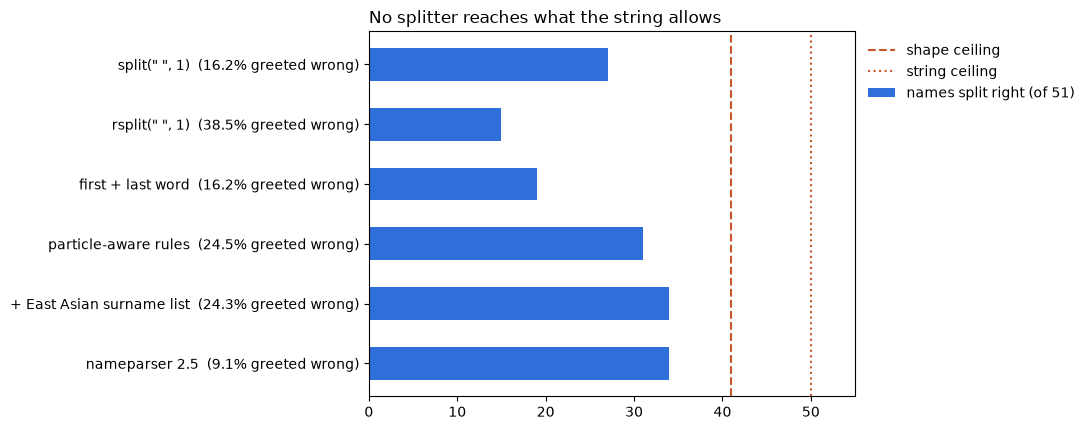

In [7]:
names = list(SPLITTERS)
both = [r["per"][n]["both_right"] for n in names]
greet = [r["per"][n]["greeted_wrong"] * 100 for n in names]
fig, ax = plt.subplots(figsize=(11, 4.4))
y = range(len(names))
ax.barh(list(y), both, color="#2f6fdb", height=0.55, label=f"names split right (of {r['n']})")
ax.axvline(r["ceiling"]["by_shape"], color="#c8562b", ls="--", label="shape ceiling")
ax.axvline(r["ceiling"]["by_string"], color="#c8562b", ls=":", label="string ceiling")
ax.set_yticks(list(y), [f"{n}  ({g:.1f}% greeted wrong)" for n, g in zip(names, greet)])
ax.invert_yaxis()
ax.set_xlim(0, 55)
ax.set_title("No splitter reaches what the string allows", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- A full-name field does not contain a split; a convention assigns one, and the string does not say which.
- The library (nameparser) beats every one-liner, and still files 16 of 51 surnames wrong.
- Rule patches trade groups: a surname list fixes family-first names and breaks Western-ordered ones.
- The fix is upstream: capture given and family in separate fields, plus "what should we call you".

## 7. Try your own

In [8]:
# for s in ["Maria de Lourdes Souza", "Okonkwo, Chidi", "Le Thi Hoa"]:
#     print(s, {n: f(s) for n, f in SPLITTERS.items()})

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version splits your own
names and your own customer mix: `pip install -r requirements.txt && streamlit run app.py`.